# Đồ thị 04 KDE phân bố platelets

**Võ Minh Huy — 2311110117**

Dùng cột platelets đã làm sạch của đủ 299 hồ sơ; không dùng hai cột kết quả làm mịn. Chia giá trị cho 1.000 chỉ để trục X dễ đọc, đơn vị nghìn/µL. KDE là đường ước lượng mật độ, không phải số hồ sơ tại từng điểm.

Gaussian KDE dùng bandwidth Scott: h = độ lệch chuẩn mẫu × n^(−1/5). Cộng kernel phản xạ tại 0 để ước lượng trên miền không âm; mỗi hồ sơ vẫn chỉ có trọng số 1/n. Phép phản xạ phục vụ đồ thị, không tạo thêm hồ sơ dữ liệu.


In [1]:
from pathlib import Path
import sys
import subprocess
import numpy as np
import pandas as pd
try:
    import matplotlib.pyplot as plt
except ModuleNotFoundError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "matplotlib"])
    import matplotlib.pyplot as plt

thu_muc = Path.cwd()
if thu_muc.name == "python":
    thu_muc = thu_muc.parent
du_lieu = pd.read_csv(thu_muc / "VoMinhHuy_Heart Failure Prediction_after_Python.csv")
platelets = pd.to_numeric(du_lieu["platelets"], errors="raise")
if len(platelets) != 299 or platelets.isna().any() or not np.isfinite(platelets).all() or (platelets <= 0).any():
    raise ValueError("Cần đủ 299 giá trị platelets dương và hữu hạn.")
x = platelets.to_numpy(dtype=float) / 1000
n = len(x)
h = x.std(ddof=1) * n ** (-1/5)
if h <= 0:
    raise ValueError("Cần độ lệch chuẩn dương để vẽ KDE.")
thu_muc_kq = thu_muc / "ket_qua/21_do_thi/04_kde_platelets"
thu_muc_kq.mkdir(parents=True, exist_ok=True)
thong_ke = pd.DataFrame({"SoHoSo":[n], "MinNghin":[x.min()],
    "MedianNghin":[np.median(x)], "MeanNghin":[x.mean()],
    "MaxNghin":[x.max()], "StdMauNghin":[x.std(ddof=1)], "BandwidthScottNghin":[h]})
thong_ke.round(3)


,SoHoSo,MinNghin,MedianNghin,MeanNghin,MaxNghin,StdMauNghin,BandwidthScottNghin
0,299,25.1,259.763,263.869,850.0,94.808,30.319


In [2]:
# Kernel Gaussian tại x_i và ảnh phản xạ -x_i; chỉ vẽ t >= 0.
luoi = np.linspace(0, x.max() + 5*h, 2001)
z = (luoi[:, None] - x[None, :]) / h
z_phan_xa = (luoi[:, None] + x[None, :]) / h
mat_do = (np.exp(-0.5*z**2) + np.exp(-0.5*z_phan_xa**2)).mean(axis=1) / (h*np.sqrt(2*np.pi))
dien_tich = np.trapezoid(mat_do, luoi)
assert np.isfinite(mat_do).all() and (mat_do >= 0).all()
assert abs(dien_tich - 1) < 1e-4
duong_kde = pd.DataFrame({"PlateletsNghin":luoi, "MatDo":mat_do})
kiem_tra = pd.DataFrame({"SoHoSo":[n], "DienTichXapXi":[dien_tich],
    "MienKhongAm":[bool((luoi >= 0).all())], "KhongConThieu":[bool(platelets.notna().all())]})
kiem_tra


,SoHoSo,DienTichXapXi,MienKhongAm,KhongConThieu
0,299,1.0,True,True


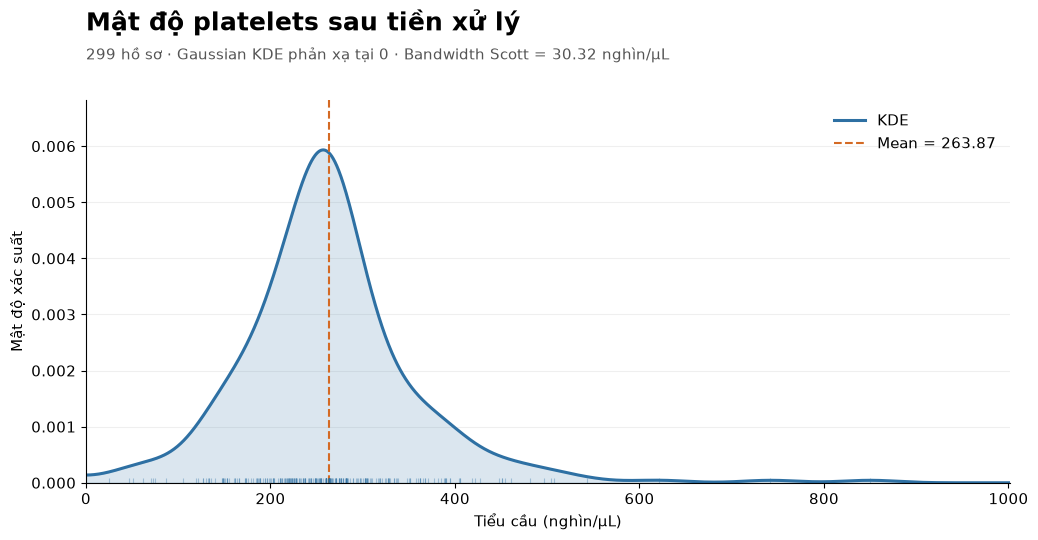

In [3]:
plt.rcParams.update({"font.family":"DejaVu Sans", "font.size":11})
fig, ax = plt.subplots(figsize=(10.5, 5.8))
fig.subplots_adjust(top=0.82, bottom=0.16, left=0.10, right=0.98)
fig.text(0.10, 0.94, "Mật độ platelets sau tiền xử lý", fontsize=18, weight="bold")
fig.text(0.10, 0.89, f"299 hồ sơ · Gaussian KDE phản xạ tại 0 · Bandwidth Scott = {h:.2f} nghìn/µL", color="#555555")
ax.plot(luoi, mat_do, color="#2E70A3", linewidth=2.2, label="KDE")
ax.fill_between(luoi, mat_do, color="#2E70A3", alpha=0.17)
ax.axvline(x.mean(), color="#D46A24", linestyle="--", label=f"Mean = {x.mean():.2f}")
# Các vạch ngắn ở đáy thể hiện vị trí quan sát; trùng giá trị có thể chồng nhau.
ax.plot(x, np.zeros(n), "|", color="#2E70A3", alpha=0.35, markersize=7, markeredgewidth=0.8)
ax.set(xlabel="Tiểu cầu (nghìn/µL)", ylabel="Mật độ xác suất", xlim=(0,luoi[-1]), ylim=(0,mat_do.max()*1.15))
ax.ticklabel_format(axis="y", style="plain", useOffset=False)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top","right"]].set_visible(False)
ax.legend(frameon=False, loc="upper right")
fig.savefig(thu_muc_kq / "04_kde_platelets.png", dpi=300, bbox_inches="tight", facecolor="white")
thong_ke.to_csv(thu_muc_kq / "thong_ke_python.csv", index=False, encoding="utf-8-sig")
kiem_tra.to_csv(thu_muc_kq / "kiem_tra_python.csv", index=False, encoding="utf-8-sig")
duong_kde.to_csv(thu_muc_kq / "duong_kde_python.csv", index=False, encoding="utf-8-sig")
plt.show()


## Nhận xét

Đường KDE cho thấy vùng tập trung của platelets quanh các giá trị giữa, đồng thời giữ phần đuôi phía giá trị cao. Trục Y là mật độ; diện tích dưới đường xấp xỉ 1, không đọc chiều cao như số bệnh nhân hay xác suất tại một giá trị đơn lẻ.

Hình dạng đường phụ thuộc bandwidth. Các gợn nhỏ chưa đủ chứng minh có nhóm bệnh nhân riêng biệt. KDE dùng dữ liệu sau xử lý, bao gồm 20 giá trị đã điền ở N04; các giá trị này cũng góp vào vùng tập trung. Đây là phép ước lượng để vẽ, không thay platelets bằng giá trị mới và không ghi đè file after.
